# GĐ 3 (phần 2): CHI-SQUARE + HỒI QUY LOGISTIC

Hoàn tất 2 mục còn lại trong phần việc của Thành viên 1 theo bảng phân công:
- **Kiểm định Chi-square** — mức độ ô nhiễm (định tính) có phụ thuộc vào mùa (định tính) không?
- **Hồi quy Logistic** — dự đoán xác suất một ngày là "ô nhiễm nặng", làm mốc so sánh cho các mô hình ML của Thành viên 2.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix,
                              accuracy_score, precision_score, recall_score, f1_score)

df = pd.read_csv("../01_Data/aqi_hcm_daily.csv", parse_dates=["date"])
print(f"Da doc {len(df)} dong, {df.shape[1]} cot")
df.head(3)

Da doc 629 dong, 16 cot


,date,pm25,pm25_cov,temperature,temperature_cov,humidity,humidity_cov,wind,rain,month,dow,mua,nang,aqi_cat,pbl_sang_m,ap_suat
0,2024-11-19,31.2,29.0,28.8,29.0,57.9,29.0,8.9,0.9,11,1,Mua kho,0,Trung binh,110.714286,1008.6
1,2024-11-20,36.6,100.0,28.9,100.0,54.1,100.0,13.0,1.4,11,2,Mua kho,1,Kem (nhay cam),82.142857,1008.3
2,2024-11-21,42.2,100.0,28.9,100.0,53.5,100.0,8.7,5.9,11,3,Mua kho,1,Kem (nhay cam),137.142857,1007.7


---
# PHẦN A — Kiểm định Chi-square

## A1. Khi nào dùng Chi-square?


**Bản chất Chi-square:** so sánh **tần số QUAN SÁT được** (đếm thực tế trong dữ liệu) với **tần số KỲ VỌNG** (số ngày lẽ ra phải rơi vào mỗi ô nếu 2 biến hoàn toàn không liên quan gì nhau). Lệch càng nhiều → χ² càng lớn → càng có bằng chứng 2 biến phụ thuộc nhau.

- **H0:** mức độ ô nhiễm ĐỘC LẬP với mùa (biết mùa cũng không đoán được mức ô nhiễm)
- **H1:** 2 biến có liên hệ

**Cặp biến chọn ở đây:** `aqi_cat` (mức ô nhiễm theo ngưỡng EPA) × `mua` (mùa khô / mùa mưa) — cả hai đều là biến định tính.

## A2. Bảng tần số chéo (contingency table)

Đếm số ngày rơi vào từng ô: mỗi hàng là 1 mức ô nhiễm, mỗi cột là 1 mùa.

In [2]:
# crosstab: dem so ngay theo tung cap (muc o nhiem, mua)
bang_cheo = pd.crosstab(df["aqi_cat"], df["mua"])
print("TAN SO QUAN SAT (so ngay thuc te)")
print("-" * 50)
print(bang_cheo)
print()

# Xem theo ty le % de de so sanh giua 2 mua
ty_le = pd.crosstab(df["aqi_cat"], df["mua"], normalize="columns") * 100
print("TY LE % TRONG TUNG MUA")
print("-" * 50)
print(ty_le.round(1))

TAN SO QUAN SAT (so ngay thuc te)
--------------------------------------------------
mua             Mua kho  Mua mua
aqi_cat                         
Kem (nhay cam)      132       41
Trung binh          159      268
Xau                  25        4

TY LE % TRONG TUNG MUA
--------------------------------------------------
mua             Mua kho  Mua mua
aqi_cat                         
Kem (nhay cam)     41.8     13.1
Trung binh         50.3     85.6
Xau                 7.9      1.3


## A3. Chạy kiểm định + kiểm tra điều kiện

**Điều kiện áp dụng Chi-square:** tần số **kỳ vọng** ở mọi ô phải ≥ 5. Nếu có ô quá nhỏ, kết quả không đáng tin (phải gộp nhóm lại hoặc dùng kiểm định Fisher). Phải kiểm tra điều kiện này trước khi tin kết quả.

In [3]:
chi2, p_chi, dof, ky_vong = stats.chi2_contingency(bang_cheo)

print("TAN SO KY VONG (neu 2 bien HOAN TOAN doc lap)")
print("-" * 50)
print(pd.DataFrame(ky_vong, index=bang_cheo.index, columns=bang_cheo.columns).round(1))
print()
print(f"Tan so ky vong nho nhat: {ky_vong.min():.2f}", end="  ")
print("-> DAT dieu kien (>= 5)" if ky_vong.min() >= 5 else "-> VI PHAM dieu kien (< 5)!")
print()

print("KET QUA KIEM DINH CHI-SQUARE")
print("-" * 50)
print(f"Chi-square : {chi2:.4f}")
print(f"Bac tu do  : {dof}")
print(f"p-value    : {p_chi:.3e}")
print()
if p_chi < 0.05:
    print("p < 0.05 -> BAC BO H0")
    print("=> Muc do o nhiem KHONG doc lap voi mua, 2 bien CO LIEN HE THAT SU")
else:
    print("p >= 0.05 -> khong du bang chung ket luan 2 bien lien he")

TAN SO KY VONG (neu 2 bien HOAN TOAN doc lap)
--------------------------------------------------
mua             Mua kho  Mua mua
aqi_cat                         
Kem (nhay cam)     86.9     86.1
Trung binh        214.5    212.5
Xau                14.6     14.4

Tan so ky vong nho nhat: 14.43  -> DAT dieu kien (>= 5)

KET QUA KIEM DINH CHI-SQUARE
--------------------------------------------------
Chi-square : 90.8861
Bac tu do  : 2
p-value    : 1.838e-20

p < 0.05 -> BAC BO H0
=> Muc do o nhiem KHONG doc lap voi mua, 2 bien CO LIEN HE THAT SU


## A4. Liên hệ MẠNH cỡ nào? — hệ số Cramér's V

Chi-square chỉ trả lời **"có liên hệ hay không"**, không nói **"mạnh cỡ nào"** — vì χ² tăng theo cỡ mẫu (mẫu càng lớn, χ² càng dễ lớn). **Cramér's V** chuẩn hoá χ² về thang 0→1 để đo độ mạnh:

| V | Mức độ |
|---|---|
| ~0.1 | Yếu |
| ~0.3 | Trung bình |
| ~0.5 trở lên | Mạnh |

In [4]:
n = bang_cheo.values.sum()
so_chieu_nho_nhat = min(bang_cheo.shape) - 1   # min(so hang, so cot) - 1
cramer_v = np.sqrt(chi2 / (n * so_chieu_nho_nhat))

print(f"Cramer's V = {cramer_v:.3f}", end="  -> ")
if cramer_v < 0.2:
    print("lien he YEU")
elif cramer_v < 0.4:
    print("lien he TRUNG BINH")
else:
    print("lien he MANH")

Cramer's V = 0.380  -> lien he TRUNG BINH


### 💡 Insight — Chi-square

In [5]:
print("INSIGHT - MUC O NHIEM CO PHU THUOC MUA KHONG")
print("-" * 60)
print(f"Chi-square = {chi2:.2f}, p = {p_chi:.2e}, Cramer's V = {cramer_v:.3f}")
print()
for muc in bang_cheo.index:
    kho = ty_le.loc[muc, "Mua kho"]
    mua_ = ty_le.loc[muc, "Mua mua"]
    print(f"  {muc:16s}: mua kho {kho:5.1f}%  |  mua mua {mua_:5.1f}%")
print()
print("=> Ket luan cho cau hoi kinh doanh:")
print("   Muc do o nhiem PHU THUOC vao mua - khong phai ngau nhien.")
print("   Khac voi t-test (so trung binh), Chi-square cho biet ca CO CAU PHAN BO")
print("   cac muc canh bao thay doi theo mua -> dung de uoc luong SO NGAY can")
print("   canh bao cho tung mua khi lap ke hoach ca nam.")

INSIGHT - MUC O NHIEM CO PHU THUOC MUA KHONG
------------------------------------------------------------
Chi-square = 90.89, p = 1.84e-20, Cramer's V = 0.380

  Kem (nhay cam)  : mua kho  41.8%  |  mua mua  13.1%
  Trung binh      : mua kho  50.3%  |  mua mua  85.6%
  Xau             : mua kho   7.9%  |  mua mua   1.3%

=> Ket luan cho cau hoi kinh doanh:
   Muc do o nhiem PHU THUOC vao mua - khong phai ngau nhien.
   Khac voi t-test (so trung binh), Chi-square cho biet ca CO CAU PHAN BO
   cac muc canh bao thay doi theo mua -> dung de uoc luong SO NGAY can
   canh bao cho tung mua khi lap ke hoach ca nam.


---
# PHẦN B — Hồi quy Logistic

## B1. Vì sao không dùng hồi quy tuyến tính cho biến Y nhị phân?

Biến Y ở đây là `nang` — chỉ nhận 2 giá trị 0 hoặc 1. Nếu dùng hồi quy tuyến tính:
- Kết quả dự đoán có thể ra **âm** hoặc **lớn hơn 1** — vô nghĩa với xác suất
- Giả định phương sai không đổi bị vi phạm

**Hồi quy Logistic** giải quyết bằng cách ép kết quả qua hàm **sigmoid**, luôn cho ra giá trị trong khoảng (0, 1) — đọc được như một xác suất:

$$P(Y=1) = \frac{1}{1 + e^{-(b_0 + b_1 x_1 + \dots + b_k x_k)}}$$

**Ý nghĩa hệ số:** không đọc trực tiếp như hồi quy tuyến tính, mà qua **Odds Ratio = e^b**:
- OR > 1 → biến X tăng thì **tăng** khả năng ngày ô nhiễm nặng
- OR < 1 → biến X tăng thì **giảm** khả năng
- OR = 1 → không ảnh hưởng

### 📌 Cập nhật — thử thêm biến Lớp biên khí quyển (`pbl_sang_m`)

Đã test: thêm `pbl_sang_m` nâng AUC từ 0.833 → **0.852** (train/test giống hệt cách chia cũ), p-value = 0.021 — **vững** khi kiểm tra lại bằng sai số robust HC3 (p=0.019). Riêng `ap_suat` (đã giúp hồi quy tuyến tính) lại **không có ý nghĩa** ở đây (p=0.109) và còn làm giảm ý nghĩa của pbl_sang_m nếu để chung — nên **chỉ thêm pbl_sang_m, không thêm ap_suat**.

## B2. Chia train/test — và một cái bẫy phải tránh

Dữ liệu chuỗi thời gian nên phải chia **theo thời gian** (không xáo trộn ngẫu nhiên), vì trộn ngẫu nhiên sẽ để mô hình "nhìn thấy tương lai".

**Nhưng cách chia 80/20 thông thường lại dính bẫy khác ở bài này** — chạy ô dưới để thấy vấn đề.

In [6]:
n80 = int(len(df) * 0.8)
tr_xau, te_xau = df.iloc[:n80], df.iloc[n80:]

print("CACH CHIA 80/20 THONG THUONG")
print("-" * 60)
print(f"  Train: {tr_xau.date.min().date()} -> {tr_xau.date.max().date()}  "
      f"({len(tr_xau)} ngay, {100*tr_xau.nang.mean():.1f}% ngay nang)")
print(f"  Test : {te_xau.date.min().date()} -> {te_xau.date.max().date()}  "
      f"({len(te_xau)} ngay, {100*te_xau.nang.mean():.1f}% ngay nang)")
print(f"  Test roi vao cac thang: {sorted(te_xau.month.unique())}")
print()
print("=> VAN DE: 20% ngay cuoi roi TRON VEN vao mua mua")
print("   -> Tap test chi co ~8% ngay nang, trong khi train co ~38%")
print("   -> Danh gia tren tap test nay KHONG dai dien cho ca nam")

CACH CHIA 80/20 THONG THUONG
------------------------------------------------------------
  Train: 2024-11-19 -> 2026-05-18  (503 ngay, 38.2% ngay nang)
  Test : 2026-05-19 -> 2026-09-21  (126 ngay, 7.9% ngay nang)
  Test roi vao cac thang: [np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]

=> VAN DE: 20% ngay cuoi roi TRON VEN vao mua mua
   -> Tap test chi co ~8% ngay nang, trong khi train co ~38%
   -> Danh gia tren tap test nay KHONG dai dien cho ca nam


**Cách sửa:** để tập test **phủ trọn 1 chu kỳ mùa** — lấy 12 tháng cuối làm test, phần còn lại làm train. Vừa giữ đúng nguyên tắc "không nhìn thấy tương lai", vừa để tập test có đủ cả mùa khô lẫn mùa mưa.

In [7]:
moc = df.date.max() - pd.Timedelta(days=364)
train = df[df.date < moc].copy()
test = df[df.date >= moc].copy()

print("CACH CHIA DUNG: TEST = 12 THANG CUOI")
print("-" * 60)
print(f"  Train: {train.date.min().date()} -> {train.date.max().date()}  "
      f"({len(train)} ngay, {100*train.nang.mean():.1f}% ngay nang)")
print(f"  Test : {test.date.min().date()} -> {test.date.max().date()}  "
      f"({len(test)} ngay, {100*test.nang.mean():.1f}% ngay nang)")
print()
print("=> Ty le ngay nang giua train va test gan nhau -> danh gia dang tin")

CACH CHIA DUNG: TEST = 12 THANG CUOI
------------------------------------------------------------
  Train: 2024-11-19 -> 2025-09-21  (264 ngay, 30.7% ngay nang)
  Test : 2025-09-22 -> 2026-09-21  (365 ngay, 33.2% ngay nang)

=> Ty le ngay nang giua train va test gan nhau -> danh gia dang tin


## B3. Huấn luyện mô hình

In [8]:
mo_hinh_log = smf.logit("nang ~ temperature + humidity + wind + rain + pbl_sang_m",
                         data=train).fit(disp=0)
print(mo_hinh_log.summary())

                           Logit Regression Results                           
Dep. Variable:                   nang   No. Observations:                  264
Model:                          Logit   Df Residuals:                      258
Method:                           MLE   Df Model:                            5
Date:                Tue, 06 Oct 2026   Pseudo R-squ.:                  0.2138
Time:                        22:55:53   Log-Likelihood:                -127.96
converged:                       True   LL-Null:                       -162.76
Covariance Type:            nonrobust   LLR p-value:                 1.234e-13
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      25.0294      5.867      4.266      0.000      13.530      36.529
temperature    -0.5433      0.146     -3.730      0.000      -0.829      -0.258
humidity       -0.1148      0.042     -2.766    

## B4. Đọc kết quả qua Odds Ratio

`coef` trong bảng trên là hệ số trong thang log-odds — khó hình dung. Đổi sang **Odds Ratio** (`e^coef`) để đọc được bằng lời.

In [9]:
bien_x = ["temperature", "humidity", "wind", "rain", "pbl_sang_m"]

bang_or = pd.DataFrame({
    "He so (b)": mo_hinh_log.params,
    "Odds Ratio": np.exp(mo_hinh_log.params),
    "p-value": mo_hinh_log.pvalues,
}).loc[bien_x].round(4)
print("BANG ODDS RATIO")
print("-" * 60)
print(bang_or.to_string())
print()

for b in bien_x:
    orv = np.exp(mo_hinh_log.params[b])
    p = mo_hinh_log.pvalues[b]
    if p >= 0.05:
        print(f"  {b:12s}: KHONG co y nghia thong ke (p={p:.3f}) -> bo qua")
        continue
    doi = (orv - 1) * 100
    chieu = "TANG" if doi > 0 else "GIAM"
    print(f"  {b:12s}: OR={orv:.3f} -> moi 1 don vi tang, kha nang ngay nang "
          f"{chieu} {abs(doi):.1f}%")

BANG ODDS RATIO
------------------------------------------------------------
             He so (b)  Odds Ratio  p-value
temperature    -0.5433      0.5808   0.0002
humidity       -0.1148      0.8916   0.0057
wind           -0.2284      0.7958   0.0002
rain           -0.0307      0.9698   0.1755
pbl_sang_m     -0.0035      0.9965   0.0205

  temperature : OR=0.581 -> moi 1 don vi tang, kha nang ngay nang GIAM 41.9%
  humidity    : OR=0.892 -> moi 1 don vi tang, kha nang ngay nang GIAM 10.8%
  wind        : OR=0.796 -> moi 1 don vi tang, kha nang ngay nang GIAM 20.4%
  rain        : KHONG co y nghia thong ke (p=0.175) -> bo qua
  pbl_sang_m  : OR=0.996 -> moi 1 don vi tang, kha nang ngay nang GIAM 0.4%


## B5. Đánh giá mô hình — ROC / AUC

**AUC (diện tích dưới đường ROC)** đo khả năng mô hình xếp đúng thứ tự: lấy ngẫu nhiên 1 ngày nặng và 1 ngày không nặng, AUC là xác suất mô hình chấm điểm ngày nặng cao hơn.

| AUC | Đánh giá |
|---|---|
| 0.5 | Đoán mò |
| 0.7 – 0.8 | Chấp nhận được |
| 0.8 – 0.9 | Tốt |
| > 0.95 | **Đáng ngờ** — thường là rò rỉ dữ liệu |

Ưu điểm của AUC: **không phụ thuộc ngưỡng cắt**, nên so sánh giữa các mô hình được công bằng (Thành viên 2 sẽ dùng chính chỉ số này để so XGBoost/SVM với mốc Logistic này).

AUC tren tap test = 0.8523



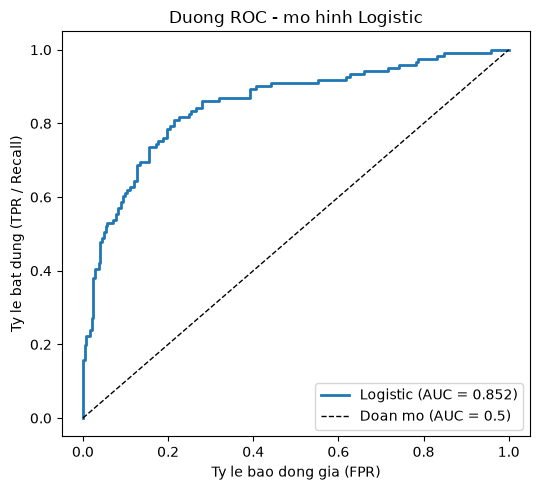

In [10]:
xac_suat_test = mo_hinh_log.predict(test)
auc = roc_auc_score(test["nang"], xac_suat_test)
print(f"AUC tren tap test = {auc:.4f}")
print()

fpr, tpr, nguong = roc_curve(test["nang"], xac_suat_test)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, linewidth=2, label=f"Logistic (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Doan mo (AUC = 0.5)")
plt.xlabel("Ty le bao dong gia (FPR)")
plt.ylabel("Ty le bat dung (TPR / Recall)")
plt.title("Duong ROC - mo hinh Logistic")
plt.legend()
plt.tight_layout()
plt.savefig("../01_Data/roc_logistic.png", dpi=120)
plt.show()

## B6. Chọn ngưỡng cắt — vì sao 0.5 thường KHÔNG phải lựa chọn tốt nhất

Mặc định ta gán "nặng" khi xác suất ≥ 0.5. Nhưng với bài toán **cảnh báo ô nhiễm**, 2 loại sai lầm có giá khác nhau:

| Loại sai | Hậu quả thực tế |
|---|---|
| Bỏ sót ngày nặng (không cảnh báo) | Người dân/sự kiện không được báo trước → **nguy hiểm sức khoẻ** |
| Báo nhầm ngày thường (cảnh báo thừa) | Chỉ tốn công chuẩn bị, hủy lịch không cần thiết |

Bỏ sót nguy hiểm hơn → nên **hạ ngưỡng xuống dưới 0.5** để bắt được nhiều ngày nặng hơn (tăng Recall), chấp nhận báo nhầm nhiều hơn.

**Cách chọn ngưỡng khách quan — chỉ số Youden:** chọn ngưỡng làm `TPR − FPR` lớn nhất, và **phải học ngưỡng từ tập TRAIN**, không được dò trên tập test (dò trên test là gian lận, làm kết quả đẹp giả).

In [11]:
# Hoc nguong tu TRAIN (khong duoc do tren test)
fpr_tr, tpr_tr, thr_tr = roc_curve(train["nang"], mo_hinh_log.predict(train))
nguong_toi_uu = thr_tr[np.argmax(tpr_tr - fpr_tr)]
print(f"Nguong toi uu hoc tu train (Youden) = {nguong_toi_uu:.3f}")
print()


def danh_gia(y_that, xac_suat, nguong, ten):
    du_doan = (xac_suat >= nguong).astype(int)
    return {
        "Cach": ten,
        "Nguong": round(nguong, 3),
        "Accuracy": round(accuracy_score(y_that, du_doan), 3),
        "Precision": round(precision_score(y_that, du_doan, zero_division=0), 3),
        "Recall": round(recall_score(y_that, du_doan, zero_division=0), 3),
        "F1": round(f1_score(y_that, du_doan, zero_division=0), 3),
    }


so_sanh = pd.DataFrame([
    danh_gia(test["nang"], xac_suat_test, 0.5, "Nguong mac dinh"),
    danh_gia(test["nang"], xac_suat_test, nguong_toi_uu, "Nguong Youden"),
])
print("SO SANH 2 NGUONG TREN TAP TEST")
print("-" * 60)
print(so_sanh.to_string(index=False))
print()

du_doan_cuoi = (xac_suat_test >= nguong_toi_uu).astype(int)
cm = confusion_matrix(test["nang"], du_doan_cuoi)
print("MA TRAN NHAM LAN (nguong Youden)")
print("-" * 40)
print(pd.DataFrame(cm,
                    index=["Thuc te: Binh thuong", "Thuc te: NANG"],
                    columns=["Du doan: Binh thuong", "Du doan: NANG"]).to_string())

Nguong toi uu hoc tu train (Youden) = 0.306

SO SANH 2 NGUONG TREN TAP TEST
------------------------------------------------------------
           Cach  Nguong  Accuracy  Precision  Recall    F1
Nguong mac dinh   0.500     0.800      0.767   0.570 0.654
  Nguong Youden   0.306     0.778      0.627   0.818 0.710

MA TRAN NHAM LAN (nguong Youden)
----------------------------------------
                      Du doan: Binh thuong  Du doan: NANG
Thuc te: Binh thuong                   185             59
Thuc te: NANG                           22             99


### 💡 Insight — hồi quy Logistic

In [12]:
print("INSIGHT - MO HINH CANH BAO SOM NGAY O NHIEM NANG")
print("-" * 62)
r_youden = so_sanh.loc[so_sanh["Cach"] == "Nguong Youden"].iloc[0]
print(f"AUC = {auc:.3f} -> mo hinh phan biet duoc ngay nang / binh thuong")
print(f"Voi nguong {r_youden['Nguong']}: bat dung {100*r_youden['Recall']:.0f}% so ngay nang thuc te")
print(f"  (Accuracy {r_youden['Accuracy']}, Precision {r_youden['Precision']}, F1 {r_youden['F1']})")
print()
print("=> Tra loi cau hoi kinh doanh:")
print("   CO THE canh bao truoc ngay o nhiem nang chi bang du lieu thoi tiet,")
print(f"   bat duoc khoang {100*r_youden['Recall']:.0f}% so ngay nang. Doi lai phai chap nhan")
print("   mot so lan bao thua - danh doi hop ly vi bo sot nguy hiem hon bao thua.")
print()
print("=> Ban giao cho Thanh vien 2:")
print(f"   Day la MOC SO SANH (baseline). Cac mo hinh ML (XGBoost/SVM/Random Forest)")
print(f"   phai vuot AUC = {auc:.3f} moi coi la co gia tri tang them.")
print("   Dung CUNG cach chia train/test nay de so sanh cong bang.")

INSIGHT - MO HINH CANH BAO SOM NGAY O NHIEM NANG
--------------------------------------------------------------
AUC = 0.852 -> mo hinh phan biet duoc ngay nang / binh thuong
Voi nguong 0.306: bat dung 82% so ngay nang thuc te
  (Accuracy 0.778, Precision 0.627, F1 0.71)

=> Tra loi cau hoi kinh doanh:
   CO THE canh bao truoc ngay o nhiem nang chi bang du lieu thoi tiet,
   bat duoc khoang 82% so ngay nang. Doi lai phai chap nhan
   mot so lan bao thua - danh doi hop ly vi bo sot nguy hiem hon bao thua.

=> Ban giao cho Thanh vien 2:
   Day la MOC SO SANH (baseline). Cac mo hinh ML (XGBoost/SVM/Random Forest)
   phai vuot AUC = 0.852 moi coi la co gia tri tang them.
   Dung CUNG cach chia train/test nay de so sanh cong bang.


## Lưu kết quả để bàn giao

In [13]:
ket_qua = pd.DataFrame([{
    "Mo hinh": "Logistic Regression (baseline)",
    "AUC": round(auc, 4),
    "Nguong": round(nguong_toi_uu, 3),
    "Accuracy": r_youden["Accuracy"],
    "Precision": r_youden["Precision"],
    "Recall": r_youden["Recall"],
    "F1": r_youden["F1"],
    "Train": f"{train.date.min().date()} -> {train.date.max().date()}",
    "Test": f"{test.date.min().date()} -> {test.date.max().date()}",
}])
ket_qua.to_csv("../01_Data/bang_ket_qua_phan_loai.csv", index=False)
print("Da luu: ../01_Data/bang_ket_qua_phan_loai.csv")
print("(Thanh vien 2 se them cac dong XGBoost/SVM/RF vao cung file nay de so sanh)")
ket_qua

Da luu: ../01_Data/bang_ket_qua_phan_loai.csv
(Thanh vien 2 se them cac dong XGBoost/SVM/RF vao cung file nay de so sanh)


,Mo hinh,AUC,Nguong,Accuracy,Precision,Recall,F1,Train,Test
0,Logistic Regression (baseline),0.8523,0.306,0.778,0.627,0.818,0.71,2024-11-19 -> 2025-09-21,2025-09-22 -> 2026-09-21
